# Cosmetic Surgery Regression Analysis
**Name:** Nisha Mahambre


**Dataset:** Surgery

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

# Load the dataset
# Make sure the file name matches exactly what is uploaded to your Colab environment
df = pd.read_excel('Surgery-data.xlsx')

# Inspect the data to ensure it loaded correctly
print(df.head())

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.info())

   STUDENT  SELFESTM  BODYSAT  IMPREAL  DESIRE  GENDER
0        1        24        3        4      11       0
1        2        20        3        4      13       0
2        3        25        4        5      11       0
3        4        22        9        4      11       1
4        5         8        1        6      18       0

Column Names:
Index(['STUDENT', 'SELFESTM', 'BODYSAT', 'IMPREAL', 'DESIRE', 'GENDER'], dtype='object')

Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   STUDENT   170 non-null    int64
 1   SELFESTM  170 non-null    int64
 2   BODYSAT   170 non-null    int64
 3   IMPREAL   170 non-null    int64
 4   DESIRE    170 non-null    int64
 5   GENDER    170 non-null    int64
dtypes: int64(6)
memory usage: 8.1 KB
None


# Define Your Model


 For this analysis, I have selected DESIRE (Desire for cosmetic surgery) as the response variable ($y$). The quantitative predictor variables ($X$) are:

$X_1$: SELFESTM (Self-esteem score)


$X_2$: BODYSAT (Body satisfaction score)


$X_3$: IMPREAL (additional survey score; exact definition per the dataset codebook)

 The symbolic form of the multiple regression model is:$$y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \beta_3 X_3 + \epsilon$$

 - DESIRE ($y$): Represents the respondent's indicated level of desire to have cosmetic surgery.
 - SELFESTM ($X_1$): Represents the respondent's measured self-esteem.
 - BODYSAT ($X_2$): Represents how satisfied the respondent is with their own body.
 - IMPREAL ($X_3$): An additional survey score. Its exact definition comes from the dataset codebook, which was not available, so it is referred to by its column name throughout.

In [2]:
# Defining the variables (Conceptual step, ensuring column names are clean)
y_var = 'DESIRE'
x_vars = ['SELFESTM', 'BODYSAT', 'IMPREAL']

print(f"Response Variable: {y_var}")
print(f"Predictor Variables: {x_vars}")

Response Variable: DESIRE
Predictor Variables: ['SELFESTM', 'BODYSAT', 'IMPREAL']


# Fit the Model
I used the statsmodels library to fit the Ordinary Least Squares (OLS) regression model defined in the corresponding analysis. The output below displays the estimated coefficients, standard errors, t-statistics, p-values, $R^2$, and Adjusted $R^2$.

In [3]:
# Fit the multiple regression model
model = smf.ols('DESIRE ~ SELFESTM + BODYSAT + IMPREAL', data=df).fit()

# Print the complete regression output table
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 DESIRE   R-squared:                       0.466
Model:                            OLS   Adj. R-squared:                  0.456
Method:                 Least Squares   F-statistic:                     48.24
Date:                Thu, 11 Dec 2025   Prob (F-statistic):           1.79e-22
Time:                        02:39:34   Log-Likelihood:                -381.82
No. Observations:                 170   AIC:                             771.6
Df Residuals:                     166   BIC:                             784.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     13.7842      0.794     17.364      0.0

# Interpret the Intercept ($\beta_0$)

The estimated intercept ($\beta_0$) is 13.7842.

Interpretation: Mathematically, this indicates that if a person had a Self-Esteem score of 0, a Body Satisfaction score of 0, and an IMPREAL score of 0, their predicted Desire for surgery would be approximately 13.78.

Real-world Sense: In this specific context, the intercept may not make complete real-world sense because it is unlikely for a respondent to have a score of "0" on all these psychological scales (scale minimums are often 1 or higher). However, it serves as the necessary baseline anchor for our regression line.

In [4]:
# Retrieve the intercept value
intercept = model.params['Intercept']
print(f"The Intercept (Beta_0) is: {intercept:.4f}")
# The intercept represents the predicted DESIRE score when all predictors are 0.
# In this context, a person with 0 self-esteem and 0 body satisfaction is a theoretical baseline, though likely not realistically observable.

The Intercept (Beta_0) is: 13.7842


# Interpret One Slope ($\beta_2$)

I have chosen the predictor BODYSAT (Body Satisfaction). Its slope ($\beta_2$) is -0.6873.

Interpretation: Holding the other variables constant (SELFESTM and IMPREAL), each 1-unit increase in Body Satisfaction is associated with a decrease of approximately 0.69 units in the predicted Desire for cosmetic surgery.

Real-world Context: This makes intuitive sense; individuals who are more satisfied with their bodies are expected to have a lower desire to undergo cosmetic surgery. This is an association in the sample and does not establish causation.


In [5]:
# Retrieve the slope for BODYSAT
slope_bodysat = model.params['BODYSAT']
print(f"The slope for BODYSAT is: {slope_bodysat:.4f}")
# Holding SELFESTM and IMPREAL constant, each 1-unit increase in BODYSAT is associated with a 0.69-point lower DESIRE score.

The slope for BODYSAT is: -0.6873


# Test One Predictor
I am testing the significance of the BODYSAT variable.
- Null Hypothesis ($H_0$): $\beta_{BODYSAT} = 0$ (Body satisfaction has no linear relationship with Desire).
- Alternative Hypothesis ($H_a$): $\beta_{BODYSAT} \neq 0$ (Body satisfaction has a linear relationship with Desire).

Results:
- t-statistic: -7.553
- p-value: approximately $2.70 \times 10^{-12}$ (which is $< 0.05$)

Conclusion: Since the p-value is less than the significance level of 0.05, we reject the null hypothesis. There is statistically significant evidence to suggest that Body Satisfaction is a predictor of the Desire for cosmetic surgery.

In [6]:
# Extract t-statistic and p-value for BODYSAT
t_stat = model.tvalues['BODYSAT']
p_val = model.pvalues['BODYSAT']

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4e}") # using scientific notation if small

if p_val < 0.05:
    print("Result: Reject Null Hypothesis. BODYSAT is a significant predictor.")
else:
    print("Result: Fail to Reject Null Hypothesis.")

T-statistic: -7.5535
P-value: 2.6969e-12
Result: Reject Null Hypothesis. BODYSAT is a significant predictor.


# Overall Model F-Test

- Null Hypothesis ($H_0$): $\beta_1 = \beta_2 = \beta_3 = 0$ (The model as a whole is not significant).
- Alternative Hypothesis ($H_a$): At least one $\beta_i \neq 0$ (At least one predictor is significant).

Results:
- F-statistic: 48.24
- Prob (F-statistic): $1.79 \times 10^{-22}$

Conclusion: The p-value is virtually zero ($< 0.05$). We reject the null hypothesis. This confirms that the overall model is statistically significant and better at predicting Desire for surgery than a model with no predictors.

In [7]:
# Extract F-statistic and its p-value
# Checking if the model as a whole explains significant variance
f_stat = model.fvalue
f_p_val = model.f_pvalue

print(f"F-statistic: {f_stat:.4f}")
print(f"Prob (F-statistic): {f_p_val:.4e}")
if f_p_val < 0.05:
    print("Result: The overall model is significant (at least one predictor works).")

F-statistic: 48.2410
Prob (F-statistic): 1.7905e-22
Result: The overall model is significant (at least one predictor works).


# Connecting ANOVA and Regression

Regression sum of squares (SSR) measures variation explained by the full model. Error sum of squares (SSE) measures residual variation. Total sum of squares (SST) measures variation around the response mean, with SST = SSR + SSE for this model with an intercept.

In statsmodels, `model.ess` is explained sum of squares, `model.ssr` is residual sum of squares, and `model.centered_tss` is total sum of squares. The naming differs from the SSR abbreviation used here for explained variation.

The overall regression F-test compares explained mean square with residual mean square and tests whether all predictor slopes are zero. This follows the explained-versus-unexplained variation logic of ANOVA. The Type I ANOVA table lists sequential contributions of individual predictors; its row-specific F-tests are not the overall model F-test and depend on predictor order.

These associations do not establish that changes in the predictors cause changes in the response.


In [ ]:
# Full-model ANOVA decomposition
anova_table = sm.stats.anova_lm(model, typ=1)

# statsmodels uses ess for explained SS and ssr for residual SS.
SSR = model.ess
SSE = model.ssr
SST = model.centered_tss

assert np.isclose(SSR + SSE, SST)
print("=== Sequential (Type I) ANOVA Table ===")
print(anova_table)
print("\n=== Full-Model Decomposition ===")
print(f"Regression Sum of Squares (SSR): {SSR:.4f}")
print(f"Error Sum of Squares (SSE):      {SSE:.4f}")
print(f"Total Sum of Squares (SST):      {SST:.4f}")
print(f"Overall model F-statistic:      {model.fvalue:.4f}")
print(f"Overall model p-value:          {model.f_pvalue:.4e}")


# Confidence Interval for a Coefficient

The output below gives the 95% confidence intervals for the intercept and all three predictors.

**Interpretation (SELFESTM):** Holding BODYSAT and IMPREAL constant, we are 95% confident that each 1-point increase in SELFESTM is associated with a change in DESIRE of between -0.0818 and 0.0597 points, on average.

**Significance check:** The interval contains zero, so we cannot conclude at the 5% level that SELFESTM has a non-zero association with DESIRE once the other predictors are in the model. This agrees with its p-value of 0.758. By contrast, the BODYSAT interval, [-0.8669, -0.5076], lies entirely below zero.


In [9]:
# Construct the 95% Confidence Intervals
# alpha=0.05 corresponds to 95% confidence
conf_intervals = model.conf_int(alpha=0.05)
conf_intervals.columns = ['Lower CI (2.5%)', 'Upper CI (97.5%)']

print("=== 95% Confidence Intervals for All Coefficients ===")
print(conf_intervals)

# 4. Extract specific values for one coefficient (e.g., SELFESTM) for interpretation
var_name = 'SELFESTM'
lower = conf_intervals.loc[var_name, 'Lower CI (2.5%)']
upper = conf_intervals.loc[var_name, 'Upper CI (97.5%)']

print(f"\nFocused Interval for {var_name}: [{lower:.4f}, {upper:.4f}]")

=== 95% Confidence Intervals for All Coefficients ===
           Lower CI (2.5%)  Upper CI (97.5%)
Intercept        12.216907         15.351508
SELFESTM         -0.081816          0.059732
BODYSAT          -0.866908         -0.507626
IMPREAL           0.264873          0.780677

Focused Interval for SELFESTM: [-0.0818, 0.0597]


# $R^2$ and Adjusted $R^2$

- **$R^2$:** 0.4658, so about 46.6% of the variation in DESIRE in this sample is explained by the linear combination of SELFESTM, BODYSAT, and IMPREAL.

- **Adjusted $R^2$:** 0.4561. It also measures explained variation, but it penalizes the number of predictors.

- **Comparison:** Adjusted $R^2$ is slightly lower than $R^2$ (0.456 vs 0.466). $R^2$ never decreases when a predictor is added, even an uninformative one, whereas adjusted $R^2$ rises only if the new predictor improves the fit by more than chance alone would. This makes it better suited to comparing models with different numbers of predictors, although it is still an in-sample measure and does not by itself protect against overfitting.


In [10]:
# R-squared and Adjusted R-squared
r_squared = model.rsquared
adj_r_squared = model.rsquared_adj

print(f"R-squared: {r_squared:.4f}")
print(f"Adjusted R-squared: {adj_r_squared:.4f}")

R-squared: 0.4658
Adjusted R-squared: 0.4561


# Residual Analysis

Looking at the Residuals vs. Fitted plot below:

- **Linearity:** The residuals scatter around zero across the full range of fitted values (roughly 8 to 16) with no U-shape or other curve, so the linearity assumption appears reasonable.

- **Equal variance:** The vertical spread is roughly constant from left to right, with no funnel shape, so there is no visible sign of heteroscedasticity.

- **Outliers:** The largest residuals are about +6.5 and -4.8. Neither stands far apart from the main cloud.

- **Normality:** The baseline model summary reports a Jarque-Bera p-value of 0.218, which gives no evidence against approximately normal residuals. The histogram in the later diagnostics cell can be checked alongside it.

These are visual and summary checks, not proof that every regression assumption holds.


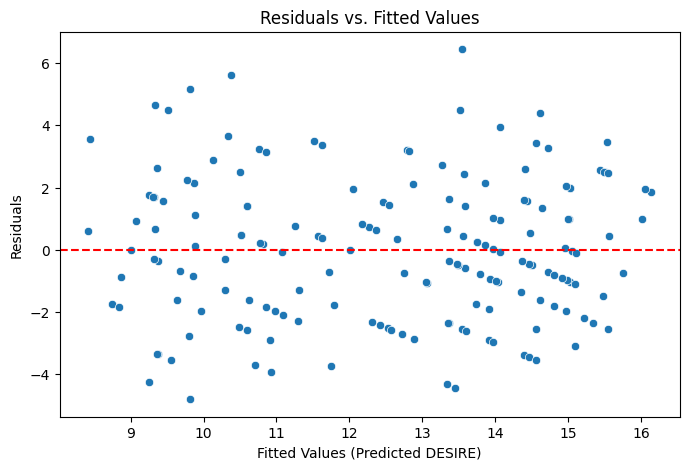

In [11]:
# Residual Analysis - Residual vs. Fitted Plot
# Get fitted values and residuals
fitted_vals = model.fittedvalues
residuals = model.resid

plt.figure(figsize=(8, 5))
sns.scatterplot(x=fitted_vals, y=residuals)
plt.axhline(0, color='red', linestyle='--') # Add a horizontal line at 0
plt.xlabel("Fitted Values (Predicted DESIRE)")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values")
plt.show()

# Confidence Interval for Mean Response
For a respondent with SELFESTM=20, BODYSAT=5, and IMPREAL=5:

- The model predicts a mean DESIRE score of approximately 12.7409.

- The 95% Confidence Interval for the mean is [12.1130, 13.3688].


- Interpretation: We are 95% confident that the average Desire score for all respondents with these specific X-values falls within this range.


In [12]:
# Confidence Interval for Mean Response
# We pick a hypothetical student with 'average' or specific values.
# Let's use: SELFESTM=20, BODYSAT=5, IMPREAL=5
new_obs = pd.DataFrame({'SELFESTM': [20], 'BODYSAT': [5], 'IMPREAL': [5]})

# Get the prediction results
prediction = model.get_prediction(new_obs)
pred_summary = prediction.summary_frame(alpha=0.05)

# Extract values for Mean Confidence Interval (mean, mean_ci_lower, mean_ci_upper)
mean_val = pred_summary['mean'][0]
lower_ci = pred_summary['mean_ci_lower'][0]
upper_ci = pred_summary['mean_ci_upper'][0]

print("=== Observation for Prediction ===")
print(new_obs)
print("\n=== 95% Confidence Interval for Mean Response ===")
print(f"Predicted Mean DESIRE: {mean_val:.4f}")
print(f"95% CI Range: [{lower_ci:.4f}, {upper_ci:.4f}]")

=== Observation for Prediction ===
   SELFESTM  BODYSAT  IMPREAL
0        20        5        5

=== 95% Confidence Interval for Mean Response ===
Predicted Mean DESIRE: 12.7409
95% CI Range: [12.1130, 13.3688]


# Prediction Interval for a New Observation

Using the same x values (SELFESTM=20, BODYSAT=5, IMPREAL=5), I computed the 95% Prediction Interval.

- **Conceptual Difference:** The Confidence Interval  estimates the *average* response for *all* people with these characteristics. The Prediction Interval  estimates the range where a *single specific individual's* score will fall.
- **Result:** The Prediction Interval is always wider than the Confidence Interval because it must account for both the uncertainty in estimating the population mean **plus** the random variation (error) of an individual data point.

In [13]:
# Prediction Interval for a New Observation
# We use the same 'pred_summary' dataframe from the corresponding analysis but look at different columns.

# Extract values for Prediction Interval (obs_ci_lower, obs_ci_upper)
lower_pi = pred_summary['obs_ci_lower'][0]
upper_pi = pred_summary['obs_ci_upper'][0]

print(f"95% Prediction Interval: [{lower_pi:.4f}, {upper_pi:.4f}]")
print(f"Confidence Interval (mean response) was: [{lower_ci:.4f}, {upper_ci:.4f}]")

95% Prediction Interval: [8.1293, 17.3525]
Confidence Interval (mean response) was: [12.1130, 13.3688]


# Interaction Term

I added an interaction between Self-Esteem and Body Satisfaction (SELFESTM:BODYSAT).

- **Significance:** The p-value for SELFESTM:BODYSAT is 0.959, well above 0.05, so the interaction is not statistically significant.
- **Interpretation:** A significant interaction would mean that the association between body satisfaction and desire depends on the level of self-esteem. There is no evidence of that here.
- **Fit:** Adjusted $R^2$ fell from 0.4561 to 0.4528 and AIC rose from 771.6 to 773.6, so the interaction does not improve the model.


In [14]:
# Adding an Interaction Term (e.g., SELFESTM * BODYSAT)
model_interaction = smf.ols('DESIRE ~ SELFESTM + BODYSAT + IMPREAL + SELFESTM:BODYSAT', data=df).fit()

print(model_interaction.summary())

                            OLS Regression Results                            
Dep. Variable:                 DESIRE   R-squared:                       0.466
Model:                            OLS   Adj. R-squared:                  0.453
Method:                 Least Squares   F-statistic:                     35.96
Date:                Thu, 11 Dec 2025   Prob (F-statistic):           1.36e-21
Time:                        02:39:36   Log-Likelihood:                -381.82
No. Observations:                 170   AIC:                             773.6
Df Residuals:                     165   BIC:                             789.3
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           13.8223      1.092  

# Quadratic Term
I added a quadratic term for Body Satisfaction ($BODYSAT^2$).

- **Significance:** The p-value for the squared term is 0.811 (coefficient -0.0068), so there is no evidence of a non-linear relationship between BODYSAT and DESIRE.
- **Interpretation:** A significant negative coefficient would indicate a concave-down relationship and a positive one a concave-up relationship. Neither is supported here.
- **Fit:** Adjusted $R^2$ is 0.4530 and AIC is 773.6, both slightly worse than the baseline.


In [15]:
# Adding a Quadratic Term (e.g., BODYSAT squared)
# We use I(BODYSAT**2) or np.power to specify the math in the formula
model_quad = smf.ols('DESIRE ~ SELFESTM + BODYSAT + IMPREAL + np.power(BODYSAT, 2)', data=df).fit()

print(model_quad.summary())

                            OLS Regression Results                            
Dep. Variable:                 DESIRE   R-squared:                       0.466
Model:                            OLS   Adj. R-squared:                  0.453
Method:                 Least Squares   F-statistic:                     35.99
Date:                Thu, 11 Dec 2025   Prob (F-statistic):           1.32e-21
Time:                        02:39:36   Log-Likelihood:                -381.79
No. Observations:                 170   AIC:                             773.6
Df Residuals:                     165   BIC:                             789.3
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               13.7101 

# Model Comparison
Comparing the Original (First-order), Interaction, and Quadratic models:

1. **Original model:** Adjusted $R^2$ 0.4561, AIC 771.6
2. **Interaction model:** Adjusted $R^2$ 0.4528 (lower), AIC 773.6 (higher, so worse)
3. **Quadratic model:** Adjusted $R^2$ 0.4530 (lower), AIC 773.6 (higher, so worse)

**Conclusion among these three:** The original first-order model is preferred. It has the highest adjusted $R^2$ and the lowest AIC, and the added terms were not significant, so the principle of parsimony favors the simpler model.

**Gender model:** The categorical extension in the next section (adjusted $R^2$ about 0.485, AIC about 763.2) fits better in-sample than all three of these models on the same response. Its improvement comes from adding a new predictor rather than transforming an existing one. All of these are in-sample measures, since no held-out data was used.


In [16]:
# Compare the three models
print(f"Original Model Adj. R-squared:    {model.rsquared_adj:.4f}")
print(f"Original Model AIC:               {model.aic:.4f}")
print("-" * 40)
print(f"Interaction Model Adj. R-squared: {model_interaction.rsquared_adj:.4f}")
print(f"Interaction Model AIC:            {model_interaction.aic:.4f}")
print("-" * 40)
print(f"Quadratic Model Adj. R-squared:   {model_quad.rsquared_adj:.4f}")
print(f"Quadratic Model AIC:              {model_quad.aic:.4f}")

Original Model Adj. R-squared:    0.4561
Original Model AIC:               771.6430
----------------------------------------
Interaction Model Adj. R-squared: 0.4528
Interaction Model AIC:            773.6403
----------------------------------------
Quadratic Model Adj. R-squared:   0.4530
Quadratic Model AIC:              773.5841


# Categorical Variable Extension

GENDER is a binary variable coded 0 and 1. In the formula, `C(GENDER)[T.1]` is the shift in the intercept for the group coded 1 relative to the baseline group coded 0. The codebook was not available, so group labels are not assigned here.

**Results (SELFESTM, BODYSAT, IMPREAL, and C(GENDER)):**

- The GENDER coefficient is -2.1865 (95% CI [-3.522, -0.851], p = 0.001). Holding the three quantitative predictors constant, the group coded 1 has an estimated DESIRE score 2.19 points lower than the group coded 0.
- Adjusted $R^2$ rises from 0.4561 to about 0.485, and AIC falls from 771.6 to 763.2.
- The other coefficients change when GENDER is added. BODYSAT shrinks from -0.6873 to -0.3223 (p = 0.026), which suggests BODYSAT and GENDER are related in this sample. SELFESTM remains non-significant (p = 0.193).

This is an association in the sample and does not show that group membership causes the difference.


In [17]:
# Adding a Categorical Variable (GENDER)
# GENDER is coded 0 and 1; group labels require the dataset codebook
model_gender = smf.ols('DESIRE ~ SELFESTM + BODYSAT + IMPREAL + C(GENDER)', data=df).fit()

print(model_gender.summary())

# Extracting the coefficient for Gender
print("\nCoefficient for Gender (Category 1 vs Baseline 0):")
print(model_gender.params['C(GENDER)[T.1]'])

                            OLS Regression Results                            
Dep. Variable:                 DESIRE   R-squared:                       0.498
Model:                            OLS   Adj. R-squared:                  0.485
Method:                 Least Squares   F-statistic:                     40.85
Date:                Thu, 11 Dec 2025   Prob (F-statistic):           9.19e-24
Time:                        02:39:36   Log-Likelihood:                -376.61
No. Observations:                 170   AIC:                             763.2
Df Residuals:                     165   BIC:                             778.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         14.0107      0.775     18.

# Linking Back to ANOVA Concepts

The overall regression F-statistic compares explained variability per model degree of freedom with residual variability per residual degree of freedom. It tests the joint null hypothesis that all non-intercept coefficients are zero.

The sequential Type I ANOVA table below reports separate tests for each predictor added in formula order. Those row-specific F-statistics do not equal the overall model F-statistic.

A regression containing only an intercept and dummy variables for a categorical factor is equivalent to one-way ANOVA for that factor. Adding quantitative predictors extends the analysis to adjusted group comparisons.


In [ ]:
# Sequential ANOVA contributions and the separate overall model test
anova_table = sm.stats.anova_lm(model, typ=1)
print("Sequential (Type I) ANOVA Table:")
print(anova_table)
print(f"\nOverall model F-statistic: {model.fvalue:.4f}")
print(f"Overall model p-value: {model.f_pvalue:.4e}")


# Further Model Exploration
Given the analysis, other potential models to try might include:


- Log Transformation: A funnel-shaped residual plot (heteroscedasticity) would motivate taking the natural log of the response (np.log(DESIRE)). The residual plot here showed no funnel, so this model is explored only as a robustness check.

- More Interactions: We only tested one interaction (SELFESTM * BODYSAT). It is possible that GENDER interacts with BODYSAT (e.g., body satisfaction might affect men and women differently regarding surgery desire).

- Variable Selection: If we had more variables, we could use Stepwise Regression or LASSO to automatically select the most predictive features.

Example:

I explored a log-transformed response model. Its adjusted R-squared is 0.4503 on the log scale, compared with 0.4561 for the original response. These measures describe different response scales and do not by themselves establish which model predicts better.

The displayed AIC values (-56.81 for log(DESIRE) and 771.64 for DESIRE) cannot be directly compared without accounting for the response transformation in the likelihood. The lower displayed log-model AIC is therefore not evidence of a better fit. A useful comparison would assess residual assumptions and held-out prediction errors on a common original response scale, with suitable retransformation of log-model predictions.


=== Multicollinearity Check (VIF) ===
   Variable        VIF
0     const  20.006766
1  SELFESTM   2.362937
2   BODYSAT   2.345685
3   IMPREAL   1.029264

Interpretation: VIF values < 5 indicate no serious multicollinearity issues.

=== Alternative Model: Log-Transformed Response ===
                            OLS Regression Results                            
Dep. Variable:         np.log(DESIRE)   R-squared:                       0.460
Model:                            OLS   Adj. R-squared:                  0.450
Method:                 Least Squares   F-statistic:                     47.14
Date:                Thu, 11 Dec 2025   Prob (F-statistic):           4.31e-22
Time:                        02:39:36   Log-Likelihood:                 32.403
No. Observations:                 170   AIC:                            -56.81
Df Residuals:                     166   BIC:                            -44.26
Df Model:                           3                                         
Covar

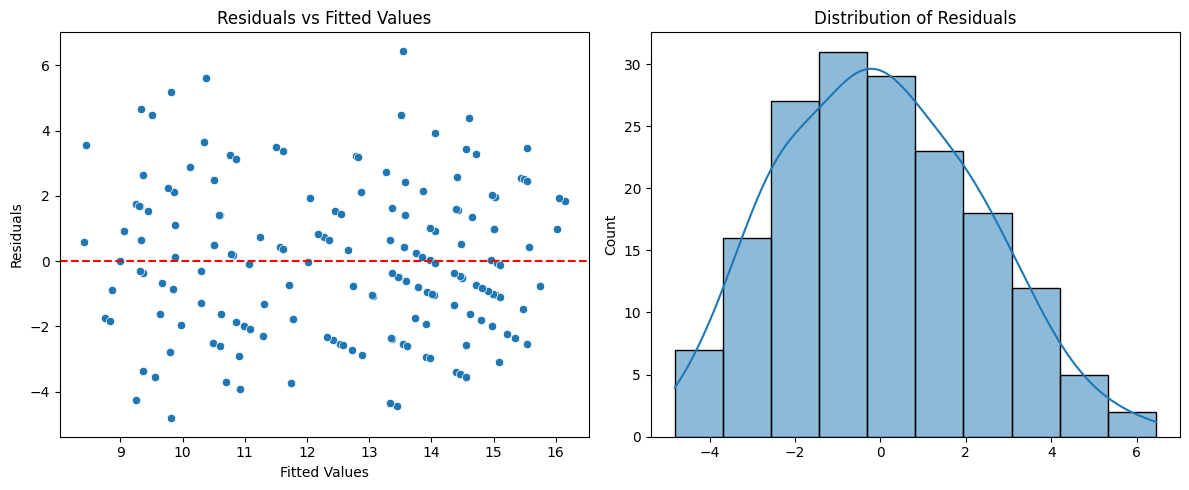

In [19]:
#Further Model Exploration - Advanced Diagnostics and Alternative Models

from statsmodels.stats.outliers_influence import variance_inflation_factor

# --- Step 1: Check for Multicollinearity (VIF) ---
# VIF above roughly 5 to 10 suggests problematic multicollinearity.
# We create a dataframe of just the predictors for this check.
X_variables = df[['SELFESTM', 'BODYSAT', 'IMPREAL']]
# Add a constant because VIF requires an intercept
X_with_const = sm.add_constant(X_variables)

vif_data = pd.DataFrame()
vif_data["Variable"] = X_with_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_with_const.values, i)
                   for i in range(X_with_const.shape[1])]

print("=== Multicollinearity Check (VIF) ===")
# The constant is needed to compute VIFs but is not a predictor, so it is not reported
print(vif_data[vif_data["Variable"] != "const"])
print("\nInterpretation: VIF values < 5 indicate no serious multicollinearity issues.\n")

# --- Step 2: Fit a Log-Transformed Model ---
# Sometimes relationships are multiplicative, not additive.
# We try predicting the Natural Log of DESIRE instead of raw DESIRE.
model_log = smf.ols('np.log(DESIRE) ~ SELFESTM + BODYSAT + IMPREAL', data=df).fit()

print("=== Alternative Model: Log-Transformed Response ===")
print(model_log.summary())

# --- Step 3: Compare Performance ---
# We compare the AIC (Lower is better) and Adj. R-squared (Higher is better)
print("\n=== Model Comparison: Linear vs. Log-Transformed ===")
print(f"Original Linear Model AIC: {model.aic:.4f}")
print(f"Log-Transformed Model AIC: {model_log.aic:.4f} (Note: AIC scales differ by transformation, use with caution)")
print(f"Original Model Adj. R-squared: {model.rsquared_adj:.4f}")
print(f"Log Model Adj. R-squared:      {model_log.rsquared_adj:.4f}")


# Residual Plots (Linearity & Normality)
# Using matplotlib and seaborn
residuals = model.resid
fitted_vals = model.fittedvalues

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Residuals vs Fitted (Check for patterns/linearity)
sns.scatterplot(x=fitted_vals, y=residuals, ax=ax[0])
ax[0].axhline(0, color='red', linestyle='--')
ax[0].set_xlabel('Fitted Values')
ax[0].set_ylabel('Residuals')
ax[0].set_title('Residuals vs Fitted Values')

# Plot 2: Histogram of Residuals (Check for Normality)
sns.histplot(residuals, kde=True, ax=ax[1])
ax[1].set_title('Distribution of Residuals')

plt.tight_layout()
plt.show()